<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Learning-Langchain-AI-Agent/blob/main/excercise/20261102_Text_Representation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title **원문**

corpus = [
    'This is the first document.',
    'This document is the second document.',
    'And this is the third one.',
    'Is this the first document?',
]

In [2]:
# @title **1. Tokenization**

print("=== [1단계] 원본 텍스트 (Raw Text) ===")
for i, text in enumerate(corpus):
    print(f"문장 {i+1}: {text}")

# 토큰화 (Tokenization) 단계 : 문장을 분석 단위(여기서는 단어)로 쪼개는 전처리 과정
tokenized_corpus = [text.lower().replace(".", "").split() for text in corpus]

print("\n=== [2단계] 토큰화 결과 (Tokenization) ===")
print("컴퓨터가 처리할 수 있는 최소 단위인 '토큰' 리스트로 분리됨:")
for i, tokens in enumerate(tokenized_corpus):
    print(f"토큰화된 문장 {i+1}: {tokens}")

=== [1단계] 원본 텍스트 (Raw Text) ===
문장 1: This is the first document.
문장 2: This document is the second document.
문장 3: And this is the third one.
문장 4: Is this the first document?

=== [2단계] 토큰화 결과 (Tokenization) ===
컴퓨터가 처리할 수 있는 최소 단위인 '토큰' 리스트로 분리됨:
토큰화된 문장 1: ['this', 'is', 'the', 'first', 'document']
토큰화된 문장 2: ['this', 'document', 'is', 'the', 'second', 'document']
토큰화된 문장 3: ['and', 'this', 'is', 'the', 'third', 'one']
토큰화된 문장 4: ['is', 'this', 'the', 'first', 'document?']


In [3]:
import re

# 1. 전체 코퍼스를 토큰화
def simple_tokenize(text: str) -> list:
  return re.findall(r"\b\w+\b", text.lower())

tokenized_corpus = [simple_tokenize(text) for text in corpus]

# 2. 중복을 제거한 고유 단어 사전(Vocabulary) 구축
vocab = sorted(list(set(token for tokens in tokenized_corpus for token in tokens)))

# 3. 단어별로 고유한 토큰 아이디(정수 인덱스) 부여 (딕셔너리 생성)
word_to_id = {word: idx for idx, word in enumerate(vocab)}
id_to_word = {idx: word for idx, word in enumerate(vocab)}

print("=== 단어 사전 (Word-to-ID) ===")
print(word_to_id)

# 4. 각 문장의 단어들을 토큰 아이디로 변환
indexed_corpus = [
    [word_to_id[token] for token in tokens] for tokens in tokenized_corpus
]

print("\n=== 토큰 아이디가 부여된 코퍼스 ===")
for i, ids in enumerate(indexed_corpus):
  print(f"문장 {i+1}: {ids} ({tokenized_corpus[i]})")

=== 단어 사전 (Word-to-ID) ===
{'and': 0, 'document': 1, 'first': 2, 'is': 3, 'one': 4, 'second': 5, 'the': 6, 'third': 7, 'this': 8}

=== 토큰 아이디가 부여된 코퍼스 ===
문장 1: [8, 3, 6, 2, 1] (['this', 'is', 'the', 'first', 'document'])
문장 2: [8, 1, 3, 6, 5, 1] (['this', 'document', 'is', 'the', 'second', 'document'])
문장 3: [0, 8, 3, 6, 7, 4] (['and', 'this', 'is', 'the', 'third', 'one'])
문장 4: [3, 8, 6, 2, 1] (['is', 'this', 'the', 'first', 'document'])


In [4]:
# @title **2. 원-핫 벡터(One-hot Vector)**
import tensorflow as tf

# 예시: 문장 1의 토큰 아이디 리스트 : dict_keys 객체를 list로 타입 변환
token_ids = list(id_to_word.keys())
vocab_size = 9  # 전체 단어 사전 크기

# TensorFlow의 one_hot 함수 적용
one_hot_vectors = tf.one_hot(token_ids, depth=vocab_size)

print("=== TensorFlow tf.one_hot 결과 ===")
print(id_to_word)
print(one_hot_vectors.numpy())

=== TensorFlow tf.one_hot 결과 ===
{0: 'and', 1: 'document', 2: 'first', 3: 'is', 4: 'one', 5: 'second', 6: 'the', 7: 'third', 8: 'this'}
[[1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [5]:
# @title **3. [N-gram](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)**

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(corpus)
vectorizer.get_feature_names_out()
X.toarray()

array([[0, 1, 1, 1, 0, 0, 1, 0, 1],
       [0, 2, 0, 1, 0, 1, 1, 0, 1],
       [1, 0, 0, 1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 0, 0, 1, 0, 1]])

In [6]:
import pandas as pd

pd.DataFrame(X.toarray(), columns = vectorizer.get_feature_names_out())

,and,document,first,is,one,second,the,third,this
0,0,1,1,1,0,0,1,0,1
1,0,2,0,1,0,1,1,0,1
2,1,0,0,1,1,0,1,1,1
3,0,1,1,1,0,0,1,0,1


In [7]:
vectorizer2 = CountVectorizer(analyzer='word', ngram_range=(2, 2))
X2 = vectorizer2.fit_transform(corpus)
pd.DataFrame(X2.toarray(), columns=vectorizer2.get_feature_names_out())

,and this,document is,first document,is the,is this,second document,the first,the second,the third,third one,this document,this is,this the
0,0,0,1,1,0,0,1,0,0,0,0,1,0
1,0,1,0,1,0,1,0,1,0,0,1,0,0
2,1,0,0,1,0,0,0,0,1,1,0,1,0
3,0,0,1,0,1,0,1,0,0,0,0,0,1


In [8]:
# @title **4. Bag of Words(DTM_[Document-Term Matrix](https://github.com/ancestor9/2026_Fall_Learning-Langchain-AI-Agent/blob/main/excercise/tfidf_excel_formulas_model.xlsx))**

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 예제 데이터 정의
corpus = [
    # [그룹 A: 요리/음식 그룹] - 공통 키워드: '요리', '맛집'
    "맛있는 짜장면 짬뽕 요리 맛집",  # 문서 1
    "매콤한 떡볶이 튀김 요리 맛집",  # 문서 2
    "맛있는 떡볶이 짬뽕 요리 맛집",  # 문서 3

    # [그룹 B: 우주/천문 그룹] - 공통 키워드: '우주선', '탐사'
    "태양계 행성 우주선 발사 탐사",  # 문서 4
    "은하수 별자리 망원경 탐사", # 문서 5
    "안드로메다 별자리 우주선 탐사" # 문서 6

]

# 2. TfidfVectorizer 객체 생성 및 벡터화 실행
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(corpus)

# 3. 단어 사전(Feature Names) 추출
feature_names = vectorizer.get_feature_names_out()

# 4. 판다스 데이터프레임으로 변환하여 시각적으로 확인
df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names,
    index=[f"doc {i+1}" for i in range(len(corpus))]
)

# 결과 출력
df_tfidf.round(4)

,떡볶이,맛있는,맛집,망원경,매콤한,발사,별자리,안드로메다,요리,우주선,은하수,짜장면,짬뽕,탐사,태양계,튀김,행성
doc 1,0.0000,0.4512,0.3809,0.0000,0.0000,0.0000,0.0000,0.0000,0.3809,0.0000,0.0000,0.5502,0.4512,0.0000,0.0000,0.0000,0.0000
doc 2,0.4303,0.0000,0.3633,0.0000,0.5248,0.0000,0.0000,0.0000,0.3633,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5248,0.0000
doc 3,0.4754,0.4754,0.4013,0.0000,0.0000,0.0000,0.0000,0.0000,0.4013,0.0000,0.0000,0.0000,0.4754,0.0000,0.0000,0.0000,0.0000
doc 4,0.0000,0.0000,0.0000,0.0000,0.0000,0.4908,0.0000,0.0000,0.0000,0.4024,0.0000,0.0000,0.0000,0.3398,0.4908,0.0000,0.4908
doc 5,0.0000,0.0000,0.0000,0.5633,0.0000,0.0000,0.4619,0.0000,0.0000,0.0000,0.5633,0.0000,0.0000,0.3900,0.0000,0.0000,0.0000
doc 6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4880,0.5951,0.0000,0.4880,0.0000,0.0000,0.0000,0.4120,0.0000,0.0000,0.0000


In [9]:
vectorizer = TfidfVectorizer(
    smooth_idf=True,      # IDF 분모/분자에 1을 더해 0 나눗셈 방지 (기본값 True)
    sublinear_tf=True,    # TF 계산 시 1 + log(TF) 적용하여 빈도수의 영향력 완화 (기본값 False)
    norm='l2',            # 행렬 벡터의 L2 정규화 적용 (기본값 'l2')
    ngram_range=(1, 2),   # 단어 단위 단일 및 연속 2단어 조합(Bi-gram)까지 생성
    max_features=1000     # 상위 1000개 중요 단어만 선택
)

In [10]:
# @title **5. [Word2Vec](https://radimrehurek.com/gensim/)**

!pip install gensim -q

from gensim.models import Word2Vec

corpus = [
    "This is the first document.",
    "This document is the second document.",
    "And this is the third one.",
    "Is this the first document?",
]

# 1. 토큰화 수행 (구두점 제거 및 소문자 변환)
tokenized_corpus = [text.lower().replace(".", "").split() for text in corpus]

# 2. Word2Vec 모델 학습
# vector_size: 단어를 표현할 벡터의 차원 수 (여기서는 예시로 10차원 지정)
# window: 주변 문맥을 파악할 윈도우(좌우 단어 개수) 크기
# min_count: 최소 등장 빈도 (여기서는 코퍼스가 짧으므로 1로 설정)
model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=10,
    window=2,
    min_count=1,
    epochs=100,
)

# 3. 특정 단어('document')의 Word2Vec 벡터 확인
word = "document"
vector = model.wv[word]

print(f"=== 단어 '{word}'의 Word2Vec 벡터 (10차원) ===")
print(vector)

# 4. 코퍼스 내 다른 단어와의 유사도 확인
similar_words = model.wv.most_similar("document", topn=3)
print(f"\n=== 'document'와 가장 유사한 단어 Top 3 ===")
for w, sim in similar_words:
  print(f"단어: {w}, 유사도: {sim:.4f}")

=== 단어 'document'의 Word2Vec 벡터 (10차원) ===
[-0.07538035 -0.00897307  0.09556899 -0.07297847 -0.02374488 -0.01989748
  0.08131091 -0.05874613 -0.00021044 -0.04775291]

=== 'document'와 가장 유사한 단어 Top 3 ===
단어: third, 유사도: 0.2940
단어: and, 유사도: 0.2114
단어: the, 유사도: 0.1134


## **실습과제 1.**  **[Working With Text Data](https://scikit-learn.org/1.4/tutorial/text_analytics/working_with_text_data.html)**

The goal of this guide is to explore some of the main scikit-learn tools on a single practical task: analyzing a collection of text documents (newsgroups posts) on twenty different topics.

In this section we will see how to:

> load the file contents and the categories

> extract feature vectors suitable for machine learning

> train a linear model to perform categorization

> use a grid search strategy to find a good configuration of both the feature extraction components and the classifier

In [11]:
categories = ['alt.atheism', 'soc.religion.christian',
              'comp.graphics', 'sci.med']

from sklearn.datasets import fetch_20newsgroups

twenty_train = fetch_20newsgroups(subset='train',
                                  categories=categories,
                                  shuffle=True,
                                  random_state=42)

## **실습과제 2. 다양한 Distance를 이용한 Clustering(Unsupervised Learning)**

In [12]:
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_similarity
import pandas as pd

# 1. 행별 데이터 추출
matrix = df_tfidf.values
index_labels = df_tfidf.index

# 2. 유클리디언 거리 계산
euclidean_matrix = euclidean_distances(matrix)
df_euclidean = pd.DataFrame(euclidean_matrix, index=index_labels, columns=index_labels)

# 3. 맨해튼 거리 계산
manhattan_matrix = manhattan_distances(matrix)
df_manhattan = pd.DataFrame(manhattan_matrix, index=index_labels, columns=index_labels)

# 4. 코사인 유사도 계산
cosine_matrix = cosine_similarity(matrix)
df_cosine = pd.DataFrame(cosine_matrix, index=index_labels, columns=index_labels)

# 결과 출력
print("=== 유클리디언 거리 (Euclidean Distance) ===")
print(df_euclidean.round(4))
print("\n=== 맨해튼 거리 (Manhattan Distance) ===")
print(df_manhattan.round(4))
print("\n=== 코사인 유사도 (Cosine Similarity) ===")
print(df_cosine.round(4))

=== 유클리디언 거리 (Euclidean Distance) ===
        doc 1   doc 2   doc 3   doc 4   doc 5   doc 6
doc 1  0.0000  1.2027  0.7285  1.4142  1.4142  1.4142
doc 2  1.2027  0.0000  1.0038  1.4142  1.4142  1.4142
doc 3  0.7285  1.0038  0.0000  1.4142  1.4142  1.4142
doc 4  1.4142  1.4142  1.4142  0.0000  1.3172  1.1521
doc 5  1.4142  1.4142  1.4142  1.3172  0.0000  1.1081
doc 6  1.4142  1.4142  1.4142  1.1521  1.1081  0.0000

=== 맨해튼 거리 (Manhattan Distance) ===
        doc 1   doc 2   doc 3   doc 4   doc 5   doc 6
doc 1  0.0000  2.9676  1.1147  4.4289  4.1928  4.1973
doc 2  2.9676  0.0000  2.1213  4.4211  4.1850  4.1895
doc 3  1.1147  2.1213  0.0000  4.4433  4.2071  4.2116
doc 4  4.4289  4.4211  4.4433  0.0000  3.5134  2.7130
doc 5  4.1928  4.1850  4.2071  3.5134  0.0000  2.2576
doc 6  4.1973  4.1895  4.2116  2.7130  2.2576  0.0000

=== 코사인 유사도 (Cosine Similarity) ===
        doc 1   doc 2   doc 3   doc 4   doc 5   doc 6
doc 1  1.0000  0.2768  0.7347  0.0000  0.0000  0.0000
doc 2  0.2768  1.0000  0

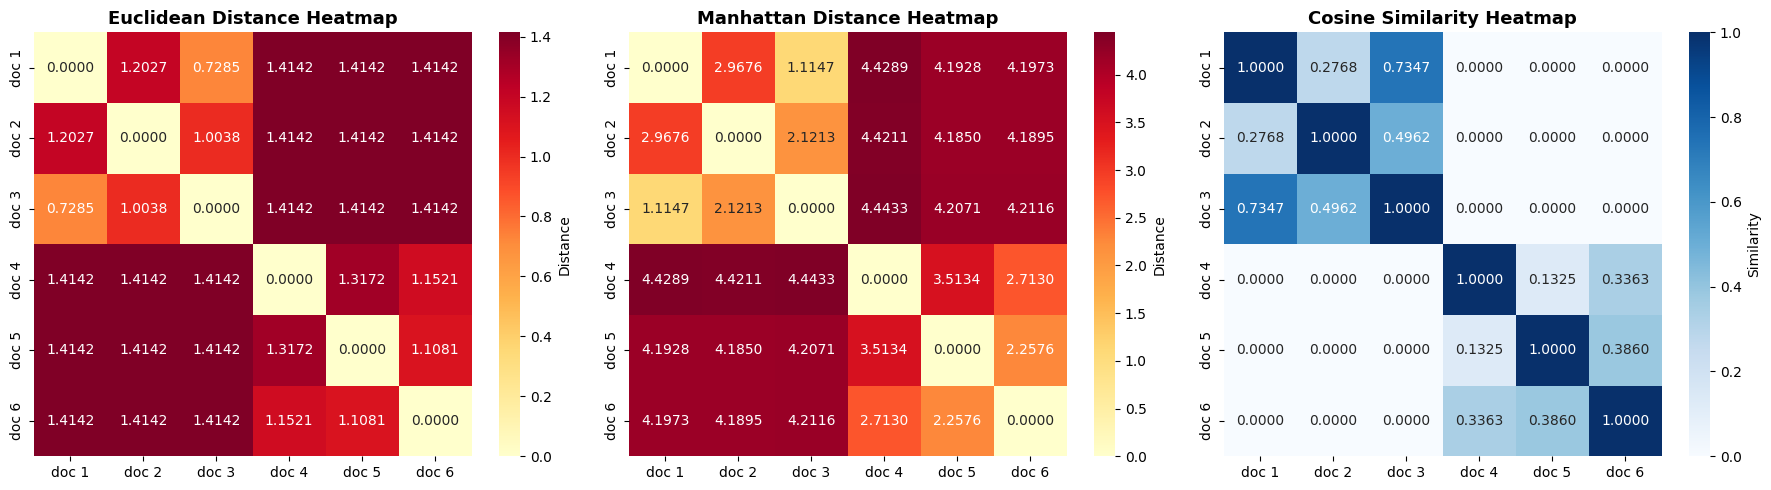

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 3개의 히트맵을 한 화면에 시각화하기 위해 서브플롯 생성
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 유클리디언 거리 히트맵
sns.heatmap(
    df_euclidean,
    annot=True,
    fmt=".4f",
    cmap="YlOrRd",
    ax=axes[0],
    cbar_kws={'label': 'Distance'}
)
axes[0].set_title("Euclidean Distance Heatmap", fontsize=13, weight='bold')

# 2. 맨해튼 거리 히트맵
sns.heatmap(
    df_manhattan,
    annot=True,
    fmt=".4f",
    cmap="YlOrRd",
    ax=axes[1],
    cbar_kws={'label': 'Distance'}
)
axes[1].set_title("Manhattan Distance Heatmap", fontsize=13, weight='bold')

# 3. 코사인 유사도 히트맵
sns.heatmap(
    df_cosine,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    ax=axes[2],
    cbar_kws={'label': 'Similarity'}
)
axes[2].set_title("Cosine Similarity Heatmap", fontsize=13, weight='bold')

plt.tight_layout()
plt.show()

In [14]:
import numpy as np

# 거리 행렬에서는 자기 자신(대각선 성분)을 제외하고 가장 작은 값을 가진 인덱스를 찾습니다.
# 유사도 행렬에서는 자기 자신을 제외하고 가장 큰 값을 가진 인덱스를 찾습니다.

def get_nearest_neighbor(df, is_similarity=False):
    nearest_neighbors = {}
    for doc in df.index:
        # 자기 자신을 제외한 시리즈 생성
        sub_series = df.loc[doc].drop(doc)
        if is_similarity:
            # 코사인 유사도는 클수록 가까움
            nearest_doc = sub_series.idxmax()
            val = sub_series.max()
        else:
            # 거리는 작을수록 가까움
            nearest_doc = sub_series.idxmin()
            val = sub_series.min()
        nearest_neighbors[doc] = (nearest_doc, round(val, 4))
    return pd.DataFrame(nearest_neighbors, index=['가장 가까운 문서', '값']).T

print("=== 유클리디언 거리 기준 Nearest Neighbor ===")
display(get_nearest_neighbor(df_euclidean, is_similarity=False))

print("\n=== 맨해튼 거리 기준 Nearest Neighbor ===")
display(get_nearest_neighbor(df_manhattan, is_similarity=False))

print("\n=== 코사인 유사도 기준 Nearest Neighbor ===")
display(get_nearest_neighbor(df_cosine, is_similarity=True))

=== 유클리디언 거리 기준 Nearest Neighbor ===


,가장 가까운 문서,값
doc 1,doc 3,0.7285
doc 2,doc 3,1.0038
doc 3,doc 1,0.7285
doc 4,doc 6,1.1521
doc 5,doc 6,1.1081
doc 6,doc 5,1.1081



=== 맨해튼 거리 기준 Nearest Neighbor ===


,가장 가까운 문서,값
doc 1,doc 3,1.1147
doc 2,doc 3,2.1213
doc 3,doc 1,1.1147
doc 4,doc 6,2.713
doc 5,doc 6,2.2576
doc 6,doc 5,2.2576



=== 코사인 유사도 기준 Nearest Neighbor ===


,가장 가까운 문서,값
doc 1,doc 3,0.7347
doc 2,doc 3,0.4962
doc 3,doc 1,0.7347
doc 4,doc 6,0.3363
doc 5,doc 6,0.386
doc 6,doc 5,0.386


In [15]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 2차원 PCA 객체 생성 및 변환
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(df_tfidf)

# 2. 결과를 데이터프레임으로 변환
df_pca = pd.DataFrame(
    pca_transformed,
    columns=['PC1', 'PC2'],
    index=df_tfidf.index
)

print("=== 2차원 PCA 좌표 ===")
display(df_pca.round(4))

# 3. 주성분 설명력(Explained Variance Ratio) 출력
print(f"\n각 주성분의 설명력: PC1={pca.explained_variance_ratio_[0]:.4f}, PC2={pca.explained_variance_ratio_[1]:.4f}")
print(f"총 설명 가능 분산: {sum(pca.explained_variance_ratio_):.4f}")

=== 2차원 PCA 좌표 ===


,PC1,PC2
doc 1,0.5703,0.0161
doc 2,0.4312,-0.0064
doc 3,0.6317,0.0138
doc 4,-0.4946,-0.6979
doc 5,-0.5270,0.6153
doc 6,-0.6115,0.0591



각 주성분의 설명력: PC1=0.4289, PC2=0.2065
총 설명 가능 분산: 0.6353


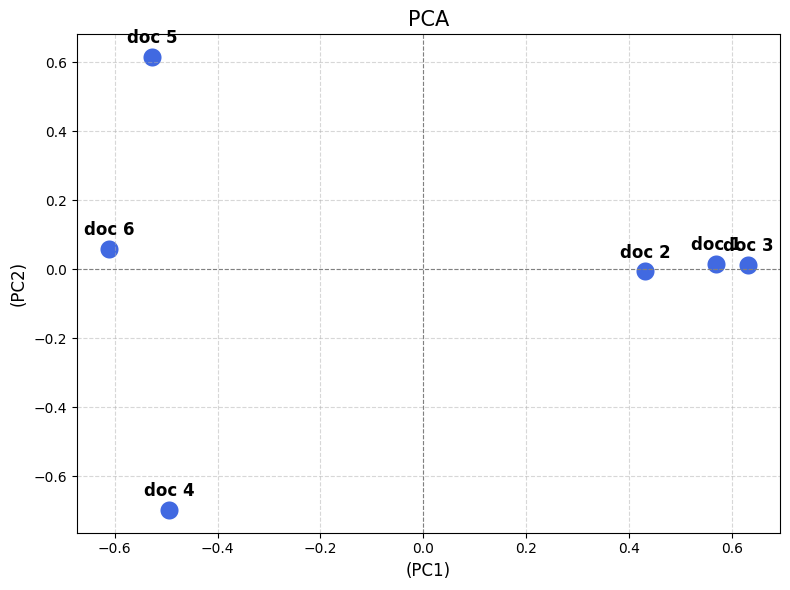

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', s=200, color='royalblue')

# 각 점에 문서 이름 주석 달기
for i, txt in enumerate(df_pca.index):
    plt.annotate(txt, (df_pca['PC1'].iloc[i], df_pca['PC2'].iloc[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=12, weight='bold')

plt.title('PCA', fontsize=15)
plt.xlabel('(PC1)', fontsize=12)
plt.ylabel('(PC2)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

=== K-Means 군집 분석 결과 (k=2) ===


,문서 내용,Cluster Lable
doc 1,맛있는 짜장면 짬뽕 요리 맛집,0
doc 2,매콤한 떡볶이 튀김 요리 맛집,0
doc 3,맛있는 떡볶이 짬뽕 요리 맛집,0
doc 4,태양계 행성 우주선 발사 탐사,1
doc 5,은하수 별자리 망원경 탐사,1
doc 6,안드로메다 별자리 우주선 탐사,1


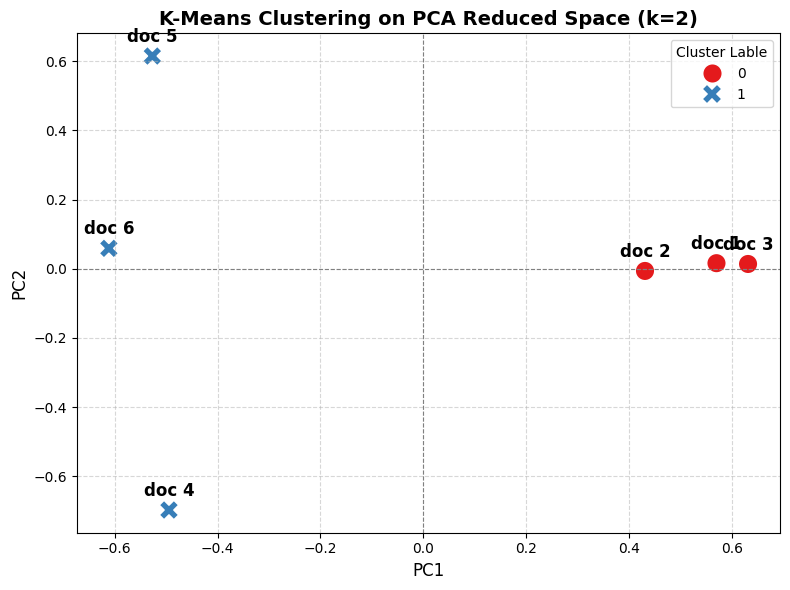

In [17]:
from sklearn.cluster import KMeans
import pandas as pd

# 5번 Word2Vec 셀에서 corpus 변수가 덮어씌워졌으므로 원래의 6개 문서 리스트를 다시 명시적으로 정의합니다.
clustering_corpus = [
    "맛있는 짜장면 짬뽕 요리 맛집",  # 문서 1
    "매콤한 떡볶이 튀김 요리 맛집",  # 문서 2
    "맛있는 떡볶이 짬뽕 요리 맛집",  # 문서 3
    "태양계 행성 우주선 발사 탐사",  # 문서 4
    "은하수 별자리 망원경 탐사", # 문서 5
    "안드로메다 별자리 우주선 탐사" # 문서 6
]

# 1. K-Means 모델 생성 및 군집화 (클러스터 수 = 2)
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(df_tfidf)

# 2. 각 문서의 군집 결과 매핑 (재정의한 clustering_corpus 사용)
df_clusters = pd.DataFrame({
    '문서 내용': clustering_corpus,
    'Cluster Lable': kmeans.labels_
}, index=df_tfidf.index)

print("=== K-Means 군집 분석 결과 (k=2) ===")
display(df_clusters)

# 3. 이전에 시각화한 PCA 2차원 공간 상에 클러스터 분포 표시
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df_pca['PC1'],
    y=df_pca['PC2'],
    hue=df_clusters['Cluster Lable'],
    palette='Set1',
    s=200,
    style=df_clusters['Cluster Lable']
)

# 각 점에 문서 이름 주석 달기
for i, txt in enumerate(df_pca.index):
    plt.annotate(txt, (df_pca['PC1'].iloc[i], df_pca['PC2'].iloc[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=12, weight='bold')

plt.title('K-Means Clustering on PCA Reduced Space (k=2)', fontsize=14, weight='bold')
plt.xlabel('PC1', fontsize=12)
plt.ylabel('PC2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

In [18]:
from sklearn.cluster import KMeans
import pandas as pd

# 5번 Word2Vec 셀에서 corpus 변수가 덮어씌워졌으므로 원래의 6개 문서 리스트를 다시 명시적으로 정의합니다.
clustering_corpus = [
    "맛있는 짜장면 짬뽕 요리 맛집",  # 문서 1
    "매콤한 떡볶이 튀김 요리 맛집",  # 문서 2
    "맛있는 떡볶이 짬뽕 요리 맛집",  # 문서 3
    "태양계 행성 우주선 발사 탐사",  # 문서 4
    "은하수 별자리 망원경 탐사", # 문서 5
    "안드로메다 별자리 우주선 탐사" # 문서 6
]

# 1. 원본 TF-IDF 고차원 피처 데이터를 그대로 사용하여 K-Means (k=2) 학습
kmeans_no_pca = KMeans(n_clusters=2, random_state=42)
kmeans_no_pca.fit(df_tfidf)

# 2. 결과 데이터프레임 생성 (재정의한 clustering_corpus 사용)
df_clusters_no_pca = pd.DataFrame({
    '문서 내용': clustering_corpus,
    'PCA 적용 안 함 (Original TF-IDF Cluster)': kmeans_no_pca.labels_
}, index=df_tfidf.index)

print("=== PCA 없이 원본 TF-IDF 기반 K-Means 군집 결과 (k=2) ===")
display(df_clusters_no_pca)

=== PCA 없이 원본 TF-IDF 기반 K-Means 군집 결과 (k=2) ===


,문서 내용,PCA 적용 안 함 (Original TF-IDF Cluster)
doc 1,맛있는 짜장면 짬뽕 요리 맛집,0
doc 2,매콤한 떡볶이 튀김 요리 맛집,0
doc 3,맛있는 떡볶이 짬뽕 요리 맛집,0
doc 4,태양계 행성 우주선 발사 탐사,1
doc 5,은하수 별자리 망원경 탐사,1
doc 6,안드로메다 별자리 우주선 탐사,1
